In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib


In [2]:
df = pd.read_csv("regression_dataset (1).csv")
df.head()

,Age,Experience,Salary
0,22,0,25000
1,23,1,28000
2,24,2,31000
3,25,3,35000
4,26,4,38000


In [4]:
df.isnull().sum()

Age           0
Experience    0
Salary        0
dtype: int64

<Axes: xlabel='Age', ylabel='Salary'>

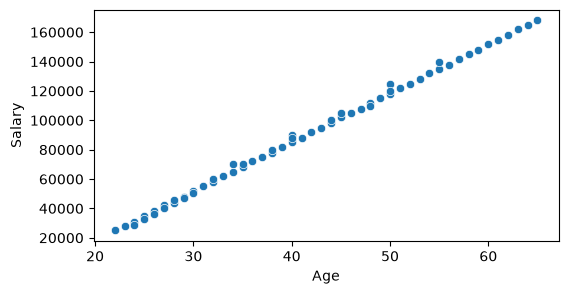

In [5]:
#let's see the relations of Age and salarly.
plt.figure(figsize=(6,3))
sns.scatterplot(x = 'Age' , y = 'Salary' ,data = df)

<Axes: xlabel='Experience', ylabel='Salary'>

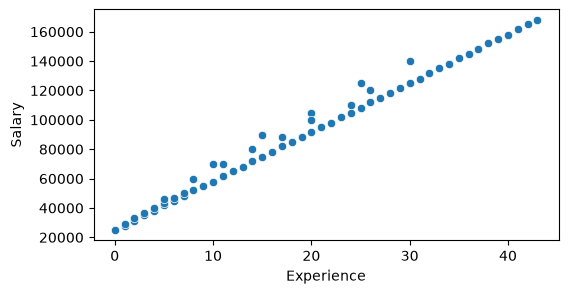

In [6]:
# let's see the relation with Experience and Salarly.
plt.figure(figsize=(6,3))
sns.scatterplot(x = 'Experience' , y = 'Salary' , data = df)

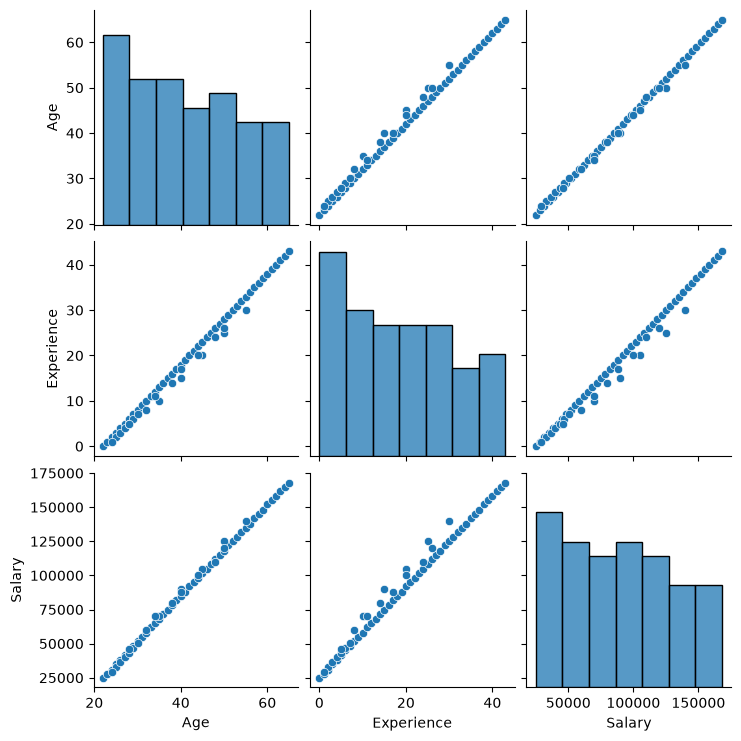

In [7]:
sns.pairplot(data=df)
plt.show()

<Axes: >

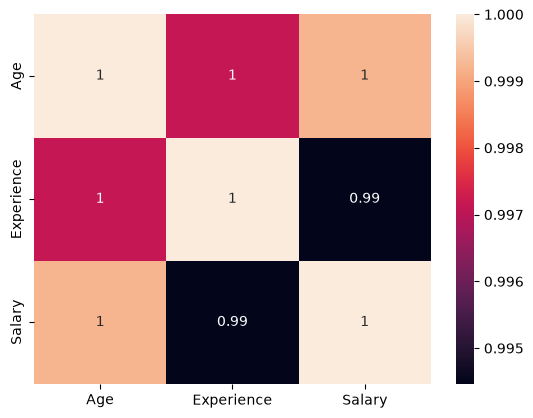

In [8]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [9]:
df.shape

(64, 3)

In [10]:
x = df.iloc[:,:-1]
y = df['Salary']

In [11]:
x.ndim

2

In [12]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [13]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[ 4501.41,-1127.07]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['Age','Experience']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-7.516e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [14]:
print(model.score(x_train,y_train) * 100)
print(model.score(x_test,y_test) * 100)


99.91563531970988
99.85591276545576


In [15]:
# y = m1x1+m2x2+c

In [16]:
model.coef_

array([ 4501.41392718, -1127.07286336])

In [17]:
model.intercept_

np.float64(-75158.83243426017)

In [18]:
# y = m1x1+m2x2+c
#y_pred = 4501.41392718 * Age + -1127.07286336 * Experience + -75158.83243426017

In [19]:
model.predict(x_test)

array([104863.33702184, 120607.96947762,  23872.27396376,  35122.3700186 ,
        40743.97928289, 145348.55226152,  77861.73098498,  64364.36672968,
       108230.80055942,  65491.43959303,  80115.8767117 ,  54241.3435382 ,
       158845.91651682])

In [20]:
#save the model.
joblib.dump(model,"model.pkl")

['model.pkl']